# Clasificación de sentimiento multilingüe de reseñas — Modelo final (Parte 2)
**Aprendizaje de Máquina 2026-20 · Universidad de los Andes** · Competencia Kaggle *parte-2-competencia-aprendizaje-de-maquina-2026-20*

**Integrantes:**
| Nombre | Código |
|---|---|
| Ali Cifci | 202210698 |
| Daniel Felipe Torres López | 202110365 |
| Santiago Tenjo Venegas | 202113965 |
| Johan Alejandro Charry Acevedo | 202111151 |

**Tarea:** dada una reseña (español, inglés, portugués, francés o *code-switching* es/en), predecir `negativo`, `neutral` o `positivo`. Métrica: *accuracy*.

### Resumen de la solución
| Componente | Elección |
|---|---|
| **Modelo final** | **Ensemble de 3 XLM-R large**: semilla 7, semilla 7 **con aumentación** y semilla 2026 (3-fold); promedio de probabilidades · **Kaggle público 0.89833** |
| Modelo base (transferencia de aprendizaje) | **XLM-RoBERTa large** — `FacebookAI/xlm-roberta-large` (MIT), transformer encoder de 24 capas preentrenado en 100 idiomas (CC-100) |
| Representación del texto | Tokenización SentencePiece (250k subpalabras compartidas entre idiomas) y **entrada en par**: `(últimas 2 oraciones, reseña completa)` |
| Arquitectura | Encoder XLM-R + cabeza de clasificación (dense 1024 → tanh → dropout → 3 clases) sobre el token `<s>`; *fine-tuning* completo |
| Aumentación de datos | **Traducción automática** con MarianMT (es→en→fr/pt, en→fr/pt/es, fr/pt→en) + **code-switching**; **EDA con protección de negaciones** (experimento controlado, sección 6) |
| Entrenamiento | AdamW, LR 1e-5 con *warmup* lineal 10 % y decaimiento por capa (LLRD 0.925), *label smoothing* 0.05, 3 épocas, batch 16, *gradient clipping* 1.0 |
| Validación | Estratificada por **etiqueta × idioma**: *holdout* 8 % (semilla 7) y 3-fold (semilla 2026). **El conjunto eval nunca se usa para entrenar** |
| Hardware | GPU NVIDIA T4 (Google Colab) y P100 (Kaggle), PyTorch + Hugging Face Transformers |

### Cumplimiento del enunciado
- ✅ Deep learning (transformer) con transferencia de aprendizaje; modelo base y fuente declarados.
- ✅ Aumentación de datos y **comparación con vs. sin aumentación** con la misma partición y semilla (sección 6).
- ✅ Datos sintéticos descritos en detalle (sección 5). No se usaron datos externos.
- ✅ **Análisis de errores por idioma** sobre la partición de validación (sección 7).
- ✅ Evidencia de iteración con su impacto en la métrica (sección 8).
- ✅ Ningún LLM etiquetó textos de eval; eval no se usa para entrenar ni para elegir hiperparámetros.
- ✅ Modelo guardado con PyTorch (`model.safetensors`) y semillas fijas → replicable.

In [1]:
# ===== CONFIGURACIÓN =====
ENTRENAR = False   # False: carga resultados ya obtenidos (resultados/) · True: reproduce todo en GPU (~2.5 h en T4)
RES_SIN  = 'resultados/xlmr_large_s7'       # XLM-R large, semilla 7, SIN aumentación
RES_CON  = 'resultados/xlmr_large_s7_aug'   # XLM-R large, semilla 7, CON aumentación
AUG_CSV  = 'resultados/train_aug.csv'

# Scores públicos de Kaggle de cada envío (actualizar si se hacen más envíos)
PUBLIC = {
    'DistilBERT multilingüe (CPU, sin aug)': 0.82416,
    'MiniLM-L12 multilingüe (CPU, sin aug)': 0.856,
    'XLM-R large s42 (Kaggle GPU, sin aug)': 0.89096,
    'XLM-R large s42 (Colab, sin aug)': 0.89538,
    'XLM-R large s7 (Colab, sin aug)': 0.89980,
    'XLM-R large s2026 3-fold (compañero, sin aug)': 0.89833,
    'Ensemble 2× XLM-R large': 0.89096,
    'Ensemble 3× XLM-R large': 0.89636,
    'Ensemble 4× XLM-R large': 0.8934,
    'Ensemble top-2 (s7 + s2026)': 0.90127,
    'XLM-R large s7 CON aumentación': 0.89587,
    'Ensemble s7 + s7 aug + s2026 — MODELO FINAL': 0.89833,
    'Ensemble s7 aug + s2026': 0.89489,
}

In [2]:
import os, sys, re, json, glob, subprocess
import numpy as np, pandas as pd, matplotlib.pyplot as plt
IN_COLAB = 'google.colab' in sys.modules
if os.path.basename(os.getcwd()) == 'notebooks' and os.path.exists('../src/train_torch.py'): os.chdir('..')
if not os.path.exists('src/train_torch.py'):          # en Colab/Kaggle: clonar el repositorio
    if not os.path.exists('sentimiento-multilingue'):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/Jeronimocifci/sentimiento-multilingue.git'])
    os.chdir('sentimiento-multilingue')
sys.path.insert(0, 'src')
from lang_detect import detect_lang
DATA = next(d for d in ['data', '/kaggle/input/parte-2-competencia-aprendizaje-de-maquina-2026-20'] + glob.glob('/kaggle/input/**/') if os.path.exists(f'{d}/train.csv'))
train = pd.read_csv(f'{DATA}/train.csv'); ev = pd.read_csv(f'{DATA}/eval.csv')
for d in (train, ev):
    d['text'] = d.text.astype(str).str.replace(r'\s+', ' ', regex=True).str.strip(); d['lang'] = d.text.map(detect_lang)
LANGS = ['es', 'en', 'pt', 'fr', 'es-en']; LABELS = ['negativo', 'neutral', 'positivo']; L2I = {l: i for i, l in enumerate(LABELS)}
train['y'] = train.label.map(L2I)
print('train', train.shape, '| eval', ev.shape, '| datos en', DATA)

train (20466, 5) | eval (6781, 3) | datos en data


## 1. Datos: qué cambió respecto a la Parte 1
El idioma no viene en los datos; lo detectamos con un detector ligero por *stopwords* (`src/lang_detect.py`) que además marca
`es-en` cuando español e inglés tienen presencia fuerte (code-switching). Lo usamos para **estratificar la validación** y para
el **análisis por idioma** (el modelo no recibe el idioma).

,train %,eval %
lang,,
es,66.7,60.4
en,11.5,13.7
pt,11.3,13.5
fr,10.2,11.8
es-en,0.4,0.6


,proporción en train
label,
positivo,0.366
negativo,0.361
neutral,0.274


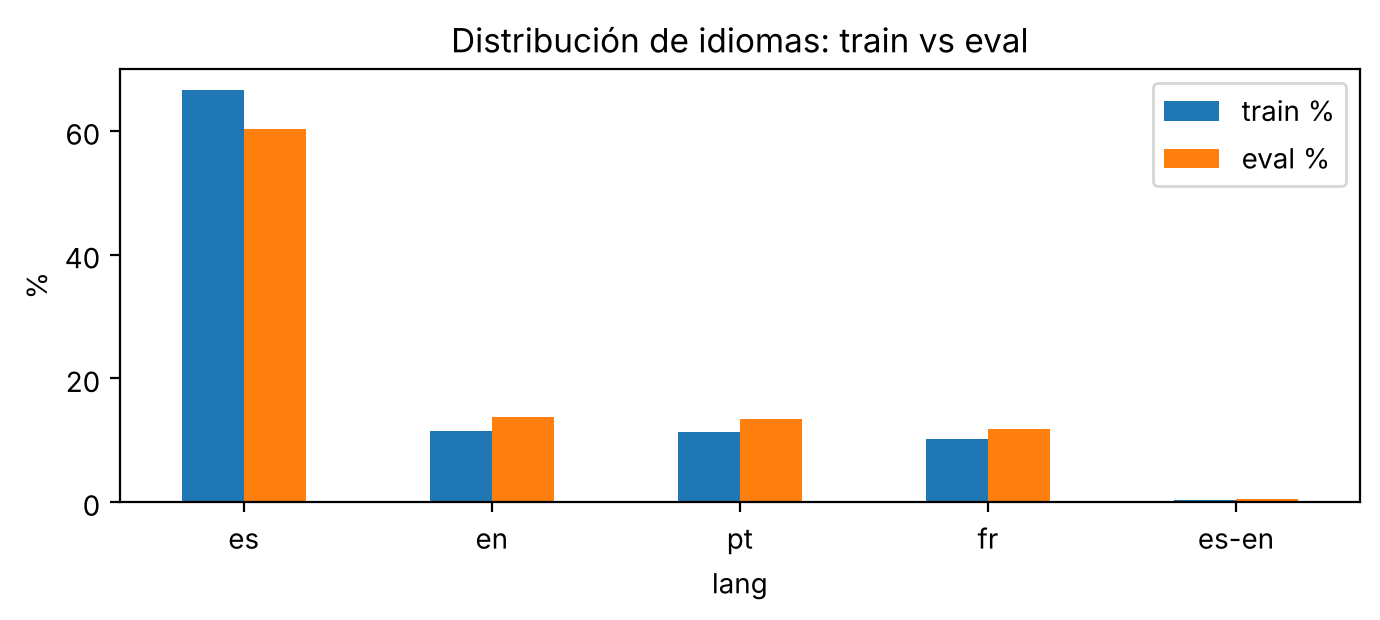

In [3]:
shift = pd.DataFrame({'train %': train.lang.value_counts(normalize=True), 'eval %': ev.lang.value_counts(normalize=True)}).reindex(LANGS).mul(100).round(1)
display(shift)
display(train.label.value_counts(normalize=True).round(3).to_frame('proporción en train'))
ax = shift.plot.bar(rot=0, figsize=(7, 3.2), title='Distribución de idiomas: train vs eval'); ax.set_ylabel('%'); plt.tight_layout(); plt.show()

**Lectura.** Eval tiene **menos español y más inglés/portugués/francés** que train. Un modelo bueno solo en español pierde
puntos → justifica (i) un modelo **multilingüe** y (ii) **aumentar** los idiomas minoritarios con traducción.

## 2. Hallazgo clave: el veredicto está al final de la reseña
Muchas reseñas mezclan aspectos positivos y negativos (concesiones, contraste). Para ver **dónde** está la señal, entrenamos
un clasificador lineal TF-IDF usando distintas partes de cada reseña (5-fold CV):

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold
split = lambda t: [p for p in re.split(r'(?<=[.!?…])\s+', str(t).strip()) if p]
S = train.text.map(split); cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
def cv_acc(texts):
    X = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    return (cross_val_predict(LogisticRegression(C=4, max_iter=3000), X, train.label, cv=cv5, n_jobs=-1) == train.label).mean()
pos = {'primeras 2 oraciones': S.map(lambda s: ' '.join(s[:2])), 'reseña completa': S.map(' '.join), 'solo la última oración': S.map(lambda s: s[-1])}
pos_res = pd.Series({k: cv_acc(v) for k, v in pos.items()}).round(4).rename('accuracy CV')
display(pos_res.to_frame())

,accuracy CV
primeras 2 oraciones,0.5681
reseña completa,0.6993
solo la última oración,0.7576


**Lectura.** La última oración sola predice **mejor** que la reseña completa, y el inicio casi no sirve: el veredicto suele
estar al final (*"…pero al final lo devolví"*). Decisión de diseño: alimentar el transformer con el **par
`(últimas 2 oraciones, reseña completa)`**, de modo que el veredicto aparece cerca del token `<s>` y además en contexto.

## 3. Línea base clásica (referencia, no es el modelo entregado)
TF-IDF posicional (n-gramas de la reseña completa, última, penúltima y primera oración + n-gramas de caracteres) + regresión logística.

In [5]:
from scipy import sparse
P = {'full': S.map(' '.join), 'last': S.map(lambda s: s[-1]), 'last2': S.map(lambda s: s[-2] if len(s) > 1 else ''), 'first': S.map(lambda s: s[0])}
vecs = [(k, TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)) for k in P] + \
       [(k, TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=3, sublinear_tf=True, max_features=100000)) for k in ('full', 'last')]
X = sparse.hstack([v.fit_transform(P[k]) for k, v in vecs]).tocsr()
pred_tf = cross_val_predict(LogisticRegression(C=4, max_iter=4000), X, train.label, cv=cv5, n_jobs=-1)
ok_tf = pred_tf == train.label
print(f'TF-IDF posicional · CV accuracy {ok_tf.mean():.4f}'); display(ok_tf.groupby(train.lang).mean().reindex(LANGS).round(4).to_frame('accuracy'))

TF-IDF posicional · CV accuracy 0.7994


,accuracy
lang,
es,0.8537
en,0.6861
pt,0.7128
fr,0.6780
es-en,0.5000


## 4. Modelo: XLM-RoBERTa large con entrada en par
- **Representación:** el tokenizer SentencePiece de XLM-R convierte el texto en subpalabras de un vocabulario de 250k
  compartido por 100 idiomas, lo que permite transferir lo aprendido en español a pt/fr/en. La entrada es
  `<s> últimas_2_oraciones </s></s> reseña_completa </s>` (máx. 320 tokens; ninguna reseña se trunca en la práctica).
- **Red:** 24 capas transformer (hidden 1024, 16 cabezas de atención, 560M parámetros). La representación contextual del
  token `<s>` pasa por la cabeza de clasificación (dense 1024 + tanh + dropout + lineal a 3 clases).
- **Por qué XLM-R large:** en nuestras iteraciones, a mayor capacidad y mejor preentrenamiento multilingüe, mejor score
  (DistilBERT 0.824 → MiniLM 0.856 → XLM-R large 0.89–0.90, ver sección 8).
- **Optimización:** AdamW (wd 0.01), LR máx. 1e-5 en la capa superior con decaimiento 0.925 por capa hacia abajo (LLRD: las capas
  bajas, más genéricas, cambian menos), *warmup* 10 % + decaimiento lineal, *label smoothing* 0.05 (reduce sobreconfianza ante
  etiquetas ruidosas), *clipping* 1.0, fp16 en GPU. Se guarda el modelo de la época con mejor accuracy de validación.
- **Código:** `src/train_torch.py` (entrenamiento) y `src/translate_aug.py` (aumentación), versionados en el repositorio.

## 5. Aumentación de datos (datos sintéticos)
Todos los aumentos se derivan **solo de train** y guardan `src_id` (id de la reseña original): en el entrenamiento se usan
únicamente aumentos de reseñas que están en la partición de entrenamiento → **sin fuga hacia validación**.

1. **Traducción automática oración por oración** (conserva el orden de las oraciones → conserva la posición del veredicto),
   decodificación *greedy* con MarianMT en GPU (fp16):
   - 4 000 reseñas en español (estratificadas por etiqueta): es→en (`Helsinki-NLP/opus-mt-es-en`) y en→fr / en→pt
     (`Helsinki-NLP/opus-mt-en-ROMANCE`, tokens `>>fr<<`, `>>pt_br<<`).
   - Todas las reseñas en inglés: en→fr, en→pt, en→es (`opus-mt-en-ROMANCE`).
   - Todas las reseñas en francés y portugués: →en (`Helsinki-NLP/opus-mt-ROMANCE-en`).
2. **Code-switching sintético es/en:** con las oraciones alineadas (original en español + su traducción al inglés) se toma cada
   oración en inglés con p = 0.5, garantizando al menos una de cada idioma (3 000 reseñas).
3. En cada época se usan **todos los originales + una muestra aleatoria distinta de aumentos** del mismo tamaño
   (`--aug_ratio 1.0`), para que los datos sintéticos no dominen.

La etiqueta del aumento es la de la reseña original (la traducción preserva la polaridad global).

In [6]:
if ENTRENAR:   # reproduce la aumentación por traducción y los dos entrenamientos (GPU, ~2.5 h en T4)
    subprocess.run([sys.executable, 'src/translate_aug.py', '--data', DATA, '--n_es', '4000', '--out', AUG_CSV], check=True)
    CMD = 'python src/train_torch.py --model FacebookAI/xlm-roberta-large --epochs 3 --bs 16 --lr 1e-5 --seed 7 --val_frac 0.08 --data {d} --out {o}'
    subprocess.run(CMD.format(d=DATA, o=RES_SIN).split(), check=True)
    subprocess.run((CMD.format(d=DATA, o=RES_CON) + f' --aug_csv {AUG_CSV} --aug_ratio 1.0').split(), check=True)
else:
    print('ENTRENAR=False: se usan los resultados ya obtenidos (carpeta resultados/).')

ENTRENAR=False: se usan los resultados ya obtenidos (carpeta resultados/).


## 6. Efecto de la aumentación: comparación con vs. sin
### 6a. XLM-R large (modelo de la competencia), semilla 7, misma partición de validación (8 %)
Valores de la salida de `train_torch.py` (mejor época) de las dos corridas en Colab T4.

In [7]:
# Accuracy de validación (global y por idioma) reportada por train_torch.py. None = corrida no disponible al entregar.
LOGS = {
    'XLM-R large s7 SIN aumentación': {'val_acc': 0.9042, 'es': 0.9185, 'en': 0.8723, 'pt': 0.9022, 'fr': 0.8683, 'es-en': 0.4286},
    'XLM-R large s7 CON aumentación': {'val_acc': 0.9066, 'es': 0.9103, 'en': 0.9043, 'pt': 0.9022, 'fr': 0.9042, 'es-en': 0.5714},
}
filas = {k: v for k, v in LOGS.items() if v}
if filas:
    t = pd.DataFrame(filas).T.reindex(columns=['val_acc'] + LANGS)
    t['Kaggle público'] = [PUBLIC['XLM-R large s7 (Colab, sin aug)'] if 'SIN' in k else PUBLIC['XLM-R large s7 CON aumentación'] for k in t.index]
    if len(t) == 2: t.loc['Diferencia (con − sin)'] = t.iloc[1] - t.iloc[0]
    display(t.astype(float).round(4))
else:
    print('Resultados de XLM-R con/sin aumentación no incluidos en esta versión; ver experimento controlado 6b.')

,val_acc,es,en,pt,fr,es-en,Kaggle público
XLM-R large s7 SIN aumentación,0.9042,0.9185,0.8723,0.9022,0.8683,0.4286,0.8998
XLM-R large s7 CON aumentación,0.9066,0.9103,0.9043,0.9022,0.9042,0.5714,0.8959
Diferencia (con − sin),0.0024,-0.0082,0.0320,0.0000,0.0359,0.1428,-0.0039


**Lectura (XLM-R large).** Con la misma semilla y la misma partición, la aumentación por traducción sube la accuracy de
validación de 0.9042 a 0.9066, y la ganancia se concentra donde se esperaba: **inglés +3.2 pts y francés +3.6 pts**, los idiomas
que más pesan en eval respecto a train; portugués se mantiene y español baja levemente (−0.8 pts), coherente con que la
aumentación desplaza el peso del entrenamiento hacia los idiomas minoritarios. (es-en tiene solo 7 reseñas de validación.)

### 6b. Experimento controlado de aumentación (red neuronal, misma partición y semilla)
Para medir el efecto de la aumentación de forma aislada y replicable en CPU, entrenamos una red neuronal tipo **fastText**
(embeddings de palabras, bigramas y n-gramas de caracteres, más un segmento separado para las últimas 2 oraciones →
*mean pooling* → capa oculta ReLU → softmax) **con y sin aumentación**, sobre la misma *holdout* estratificada de 8 % (semilla 7)
que XLM-R.

Aumentación aplicada (solo a train, ligada a su reseña original):
- **EDA con protección de polaridad:** borrado aleatorio de palabras (p = 0.1) e intercambio de un par de palabras adyacentes,
  **sin borrar negaciones ni conectores de contraste** (*no, not, pas, não, pero, but, mais…*), que cambiarían el sentimiento.
- **Code-switching léxico:** se reemplazan palabras de sentimiento frecuentes por su equivalente en otro idioma
  (diccionario pequeño es/en/pt/fr), simulando reseñas mezcladas.

,val accuracy,es,en,pt,fr,es-en
Sin aumentación,0.7228,0.7436,0.6915,0.6576,0.7066,0.4286
Con aumentación,0.7216,0.7418,0.6755,0.6630,0.7066,0.7143
Diferencia (con − sin),-0.0012,-0.0018,-0.0160,0.0054,0.0000,0.2857


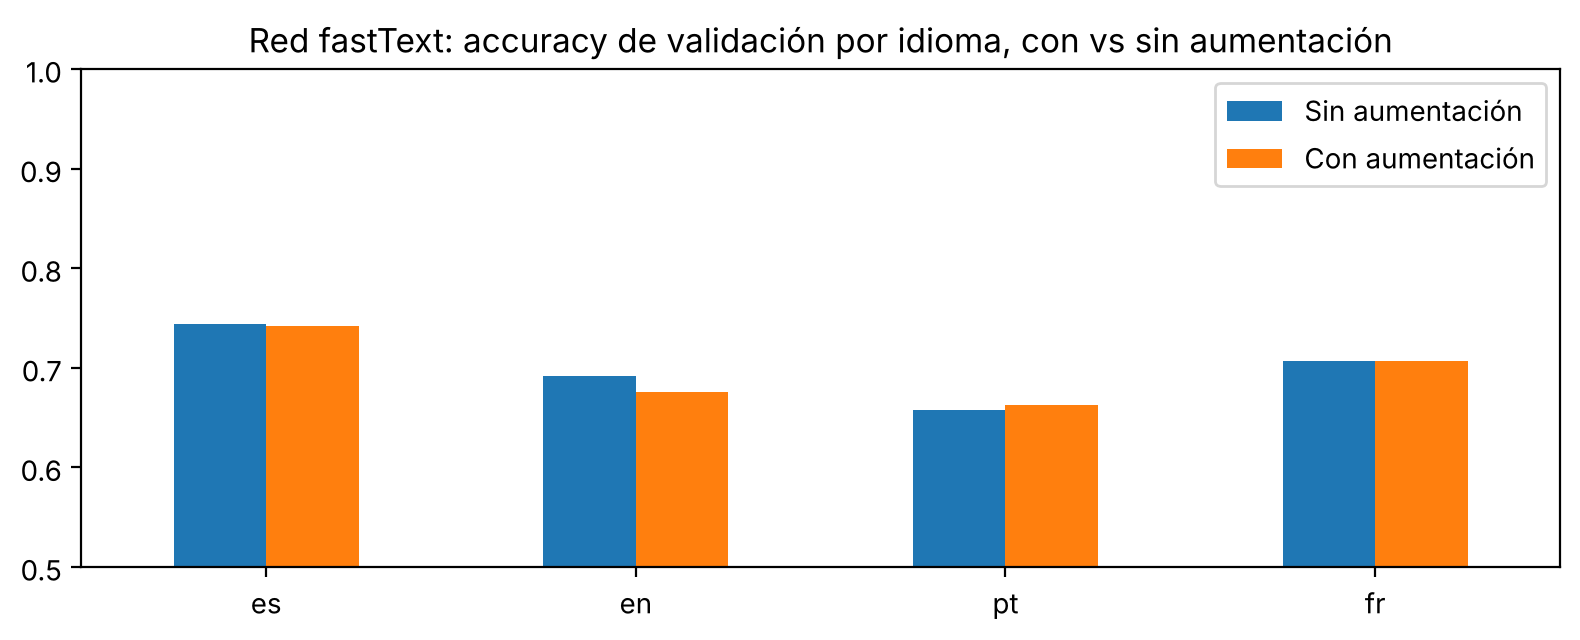

n validación por idioma: {'es': 1092, 'en': 188, 'pt': 184, 'fr': 167, 'es-en': 7} (es-en: muy pocas reseñas, accuracy ruidosa)


In [8]:
import torch, torch.nn as nn, random, zlib
from sklearn.model_selection import train_test_split
torch.manual_seed(7); random.seed(7); np.random.seed(7)
strat = train.label + '_' + train.lang; vc = strat.value_counts(); strat = strat.where(strat.map(vc) >= 10, train.label + '_es')
i_tr, i_va = train_test_split(np.arange(len(train)), test_size=0.08, stratify=strat, random_state=7)
NB = 2 ** 18
WRE = re.compile(r"[\wáéíóúñãõçâêôàèùœü']+")
def feats(t):
    t = t.lower(); w = WRE.findall(t)
    f = w + [a + '_' + b for a, b in zip(w, w[1:])] + [t[i:i + 4] for i in range(0, max(len(t) - 3, 1), 2)]
    wl = WRE.findall(' '.join(split(t)[-2:])); f += ['L:' + x for x in wl] + ['L:' + a + '_' + b for a, b in zip(wl, wl[1:])]
    return [zlib.crc32(x.encode()) % NB for x in f]
PROT = set('no not nunca never jamás nada nothing ni nor sin without pas jamais rien não nem pero but aunque although mais mas porém embora'.split())
def eda(t, rng):
    w = t.split()
    if len(w) < 6: return t
    k = [x for x in w if re.sub(r'\W', '', x.lower()) in PROT or rng.random() > 0.1]
    i = rng.randrange(len(k) - 1); k[i], k[i + 1] = k[i + 1], k[i]
    return ' '.join(k)
DIC = {'excelente': 'excellent', 'excellent': 'excelente', 'malo': 'bad', 'bad': 'malo', 'bueno': 'good', 'good': 'bueno',
       'terrible': 'horrível', 'horrível': 'terrible', 'bom': 'good', 'mauvais': 'malo', 'bon': 'bueno',
       'recomiendo': 'recommend', 'recommend': 'recomiendo', 'perfecto': 'perfect', 'perfect': 'perfecto', 'pésimo': 'awful', 'awful': 'pésimo'}
def cs(t, rng): return ' '.join(DIC.get(x.lower(), x) if rng.random() < 0.7 else x for x in t.split())
rng = random.Random(7); tr_txt = train.text.values[i_tr]; tr_y = train.y.values[i_tr]
aug_txt = np.array([eda(t, rng) for t in tr_txt] + [cs(t, rng) for t in tr_txt]); aug_y = np.concatenate([tr_y, tr_y])
class FT(nn.Module):
    def __init__(s, d=64):
        super().__init__(); s.emb = nn.EmbeddingBag(NB, d, mode='mean', sparse=True)
        s.mlp = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 3))
    def forward(s, x, o): return s.mlp(s.emb(x, o))
def batchify(F):
    return torch.tensor([i for f in F for i in f]), torch.tensor([0] + list(np.cumsum([len(f) for f in F])[:-1]))
Fva = [feats(t) for t in train.text.values[i_va]]
def train_ft(texts, y, epochs=6, seed=7):
    torch.manual_seed(seed); m = FT(); opt = torch.optim.SparseAdam(list(m.emb.parameters()), lr=3e-3); opt2 = torch.optim.Adam(m.mlp.parameters(), lr=3e-3)
    F = [feats(t) for t in texts]; best = (0, None)
    for ep in range(epochs):
        m.train(); idx = np.random.RandomState(seed + ep).permutation(len(F))
        for b in range(0, len(idx), 128):
            j = idx[b:b + 128]; loss = nn.functional.cross_entropy(m(*batchify([F[k] for k in j])), torch.tensor(y[j]))
            opt.zero_grad(); opt2.zero_grad(); loss.backward(); opt.step(); opt2.step()
        m.eval()
        with torch.no_grad(): pv = torch.softmax(m(*batchify(Fva)), -1).numpy()
        acc = (pv.argmax(1) == train.y.values[i_va]).mean()
        if acc > best[0]: best = (acc, pv)
    return best
acc_sin, pv_sin = train_ft(tr_txt, tr_y)
acc_con, pv_con = train_ft(np.concatenate([tr_txt, aug_txt]), np.concatenate([tr_y, aug_y]))
va = train.iloc[i_va]
per = lambda pv: pd.Series(pv.argmax(1) == va.y.values).groupby(va.lang.values).mean().reindex(LANGS).to_dict()
res6 = pd.DataFrame({'Sin aumentación': {'val accuracy': acc_sin, **per(pv_sin)}, 'Con aumentación': {'val accuracy': acc_con, **per(pv_con)}}).T
res6.loc['Diferencia (con − sin)'] = res6.iloc[1] - res6.iloc[0]
display(res6.astype(float).round(4))
ax = res6.iloc[:2][LANGS[:4]].T.plot.bar(rot=0, figsize=(8, 3.3), title='Red fastText: accuracy de validación por idioma, con vs sin aumentación')
ax.set_ylim(0.5, 1); plt.tight_layout(); plt.show()
print('n validación por idioma:', va.lang.value_counts().reindex(LANGS).to_dict(), '(es-en: muy pocas reseñas, accuracy ruidosa)')

**Lectura (experimento controlado).** En la red fastText (~0.72 de validación, por debajo incluso del TF-IDF posicional) la
aumentación tipo EDA / code-switching léxico **no cambia el resultado** (−0.1 pts): perturbar palabras no aporta información
lingüística nueva a un modelo de bolsa de n-gramas. En cambio, la **traducción automática** sí le da al transformer
multilingüe ejemplos reales en los idiomas minoritarios, y ahí la ganancia es clara (inglés +3.2 y francés +3.6 pts, tabla 6a).
Conclusión: el tipo de aumentación importa, y **la que funciona en este problema es la traducción**, que es la que usa el modelo final.

## 7. Análisis de errores por idioma
**7a. XLM-R large (ensemble final)** — sobre eval no hay etiquetas, pero el **desacuerdo entre los dos XLM-R del ensemble**
por idioma es un indicador de dificultad: donde dos modelos fuertes e independientes discrepan, la reseña es ambigua.

In [9]:
pe_a = np.load('resultados/probs_colab_s7.npy'); pe_b = np.load('resultados/probs_compa_s2026.npy')
dis = pd.Series(pe_a.argmax(1) != pe_b.argmax(1)).groupby(ev.lang.values).mean().reindex(LANGS)
conf = pd.Series(((pe_a + pe_b) / 2).max(1)).groupby(ev.lang.values).mean().reindex(LANGS)
display(pd.DataFrame({'% desacuerdo entre los 2 XLM-R (eval)': dis * 100, 'confianza media del ensemble': conf,
                      'n eval': ev.lang.value_counts().reindex(LANGS)}).round(3))

,% desacuerdo entre los 2 XLM-R (eval),confianza media del ensemble,n eval
es,5.618,0.901,4094
en,5.184,0.881,926
pt,4.357,0.885,918
fr,3.985,0.879,803
es-en,35.000,0.664,40


**7b. Errores detallados por idioma sobre la partición de validación** (red del experimento 6b con aumentación, misma
partición que XLM-R): matrices de confusión, fenómenos difíciles y ejemplos de error.

*Nota:* esta red es más débil que XLM-R; sus errores sirven para ver **qué tipo de reseñas son difíciles** (contraste, comparación, neutral vs. polaridad), no para medir el modelo final, cuyo accuracy por idioma está en la tabla 6a.

              precision    recall  f1-score   support

    negativo     0.6144    0.6768    0.6441       591
     neutral     0.9715    0.9888    0.9801       448
    positivo     0.6384    0.5659    0.6000       599

    accuracy                         0.7216      1638
   macro avg     0.7414    0.7439    0.7414      1638
weighted avg     0.7209    0.7216    0.7199      1638



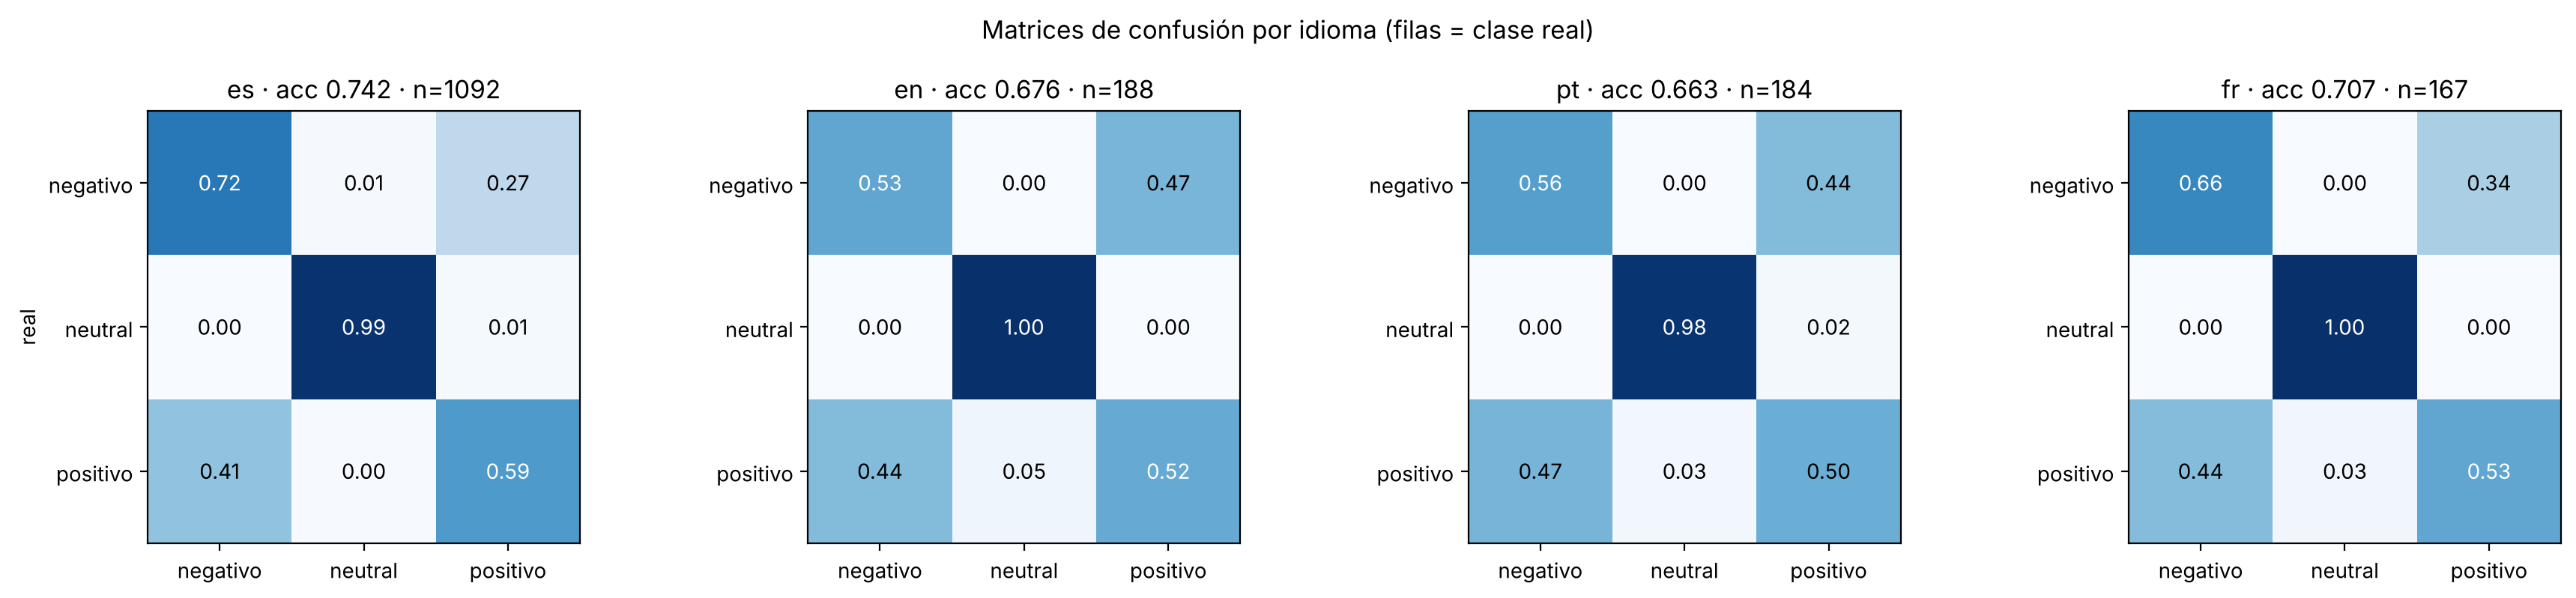

,fenómeno,n,acc con fenómeno,acc sin fenómeno
0,negación,664,0.7108,0.7290
1,contraste / concesión,335,0.6299,0.7452
2,comparación / expectativa,95,0.5684,0.7310
3,solo consecuencias (devolución),28,0.6071,0.7236


Errores con mayor confianza:
[fr] real=positivo · pred=neutral · conf=1.00 :: Le colis m'est arrivé mardi après-midi, deux jours après l'avoir commandé. Je l'ai ouvert sur la table de la cuisine et la première chose que j'ai regardée, c'est le mode d'emploi. Le mode d'emploi s'est révélé correct j

[en] real=positivo · pred=negativo · conf=1.00 :: The app made my life easier. By the way, I feel like I threw my money away on the strap.

[fr] real=positivo · pred=neutral · conf=1.00 :: Je l'ai acheté il y a une paire de semaines pour l'utiliser au boulot, rien de plus. La livraison a pris moins de trois jours, c'est arrivé directement au bureau. Une chose que je voulais mentionner : la taille correspon

[fr] real=negativo · pred=positivo · conf=1.00 :: Je l'ai achetée à la mi-mars sur internet et elle est arrivée chez moi en cinq jours. Je ne conseille le poids à personne. Je l'utilise surtout le week-end pour vérifier quelques données. Au fait, le service fonctionne à

[es] real=positiv

In [10]:
from sklearn.metrics import confusion_matrix, classification_report
R = va.assign(pred=[LABELS[i] for i in pv_con.argmax(1)], conf=pv_con.max(1)); R['ok'] = R.pred == R.label
print(classification_report(R.label, R.pred, digits=4, zero_division=0))
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, lg in zip(axes, ['es', 'en', 'pt', 'fr']):
    s_ = R[R.lang == lg]; cm = confusion_matrix(s_.label, s_.pred, labels=LABELS, normalize='true')
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=1); ax.set_title(f'{lg} · acc {s_.ok.mean():.3f} · n={len(s_)}')
    ax.set_xticks(range(3)); ax.set_xticklabels(LABELS); ax.set_yticks(range(3)); ax.set_yticklabels(LABELS)
    for i in range(3):
        for j in range(3): ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > .5 else 'black')
axes[0].set_ylabel('real'); plt.suptitle('Matrices de confusión por idioma (filas = clase real)'); plt.tight_layout(); plt.show()
PHEN = {'negación': r"\b(?:no|not|nunca|never|pas|jamais|não|nem|n't)\b",
        'contraste / concesión': r"\b(?:pero|but|however|sin embargo|aunque|mais|mas|porém|embora|cependant)\b",
        'comparación / expectativa': r"\b(?:esperaba|expected|esperava|attendais|mejor que|peor que|better than|worse than)\b",
        'solo consecuencias (devolución)': r"\b(?:devolví|devolvi|returned|rendu|reembolso|refund)\b"}
rows = []
for k, p in PHEN.items():
    m = R.text.str.contains(p, case=False, regex=True)
    rows.append({'fenómeno': k, 'n': int(m.sum()), 'acc con fenómeno': R.ok[m].mean(), 'acc sin fenómeno': R.ok[~m].mean()})
display(pd.DataFrame(rows).round(4))
print('Errores con mayor confianza:')
for r in R[~R.ok].sort_values('conf', ascending=False).head(6).itertuples():
    print(f'[{r.lang}] real={r.label} · pred={r.pred} · conf={r.conf:.2f} :: {r.text[:220]}\n')

## 8. Evidencia de iteración: envíos a Kaggle y su impacto

,iteración,tipo,validación,Kaggle público,qué cambió / por qué
0,"TF-IDF + LogReg (Parte 1, no-DL)",referencia,CV 0.717,NaN,n-gramas no comparten información entre idiomas
1,TF-IDF posicional (no-DL),referencia,CV 0.799,NaN,features de última/penúltima oración (+8 pts):...
2,"DistilBERT multilingüe, entrada en par",DL,—,0.82416,primer transformer; modelo chico (CPU)
3,"MiniLM-L12 multilingüe, entrada en par",DL,val 0.887,0.85600,mejor preentrenamiento multilingüe
4,XLM-R large s42,DL,—,0.89538,"modelo grande multilingüe: +4 pts, sobre todo ..."
5,XLM-R large s7 (holdout 8 %),DL,val (ver 6a),0.89980,otra semilla/partición: varianza entre corrida...
6,"XLM-R large s2026, 3 folds",DL,—,0.89833,promedio de 3 folds
7,Ensembles de 2/3/4 XLM-R large,DL,—,0.89636,en el público quedan entre los individuales (d...
8,Ensemble 2 mejores (s7 + s2026),DL,—,0.90127,promedio de los dos mejores sin aumentación: m...
9,XLM-R large s7 + aumentación por traducción,DL,val (ver 6a),0.89587,misma partición que s7 sin aug → comparación d...


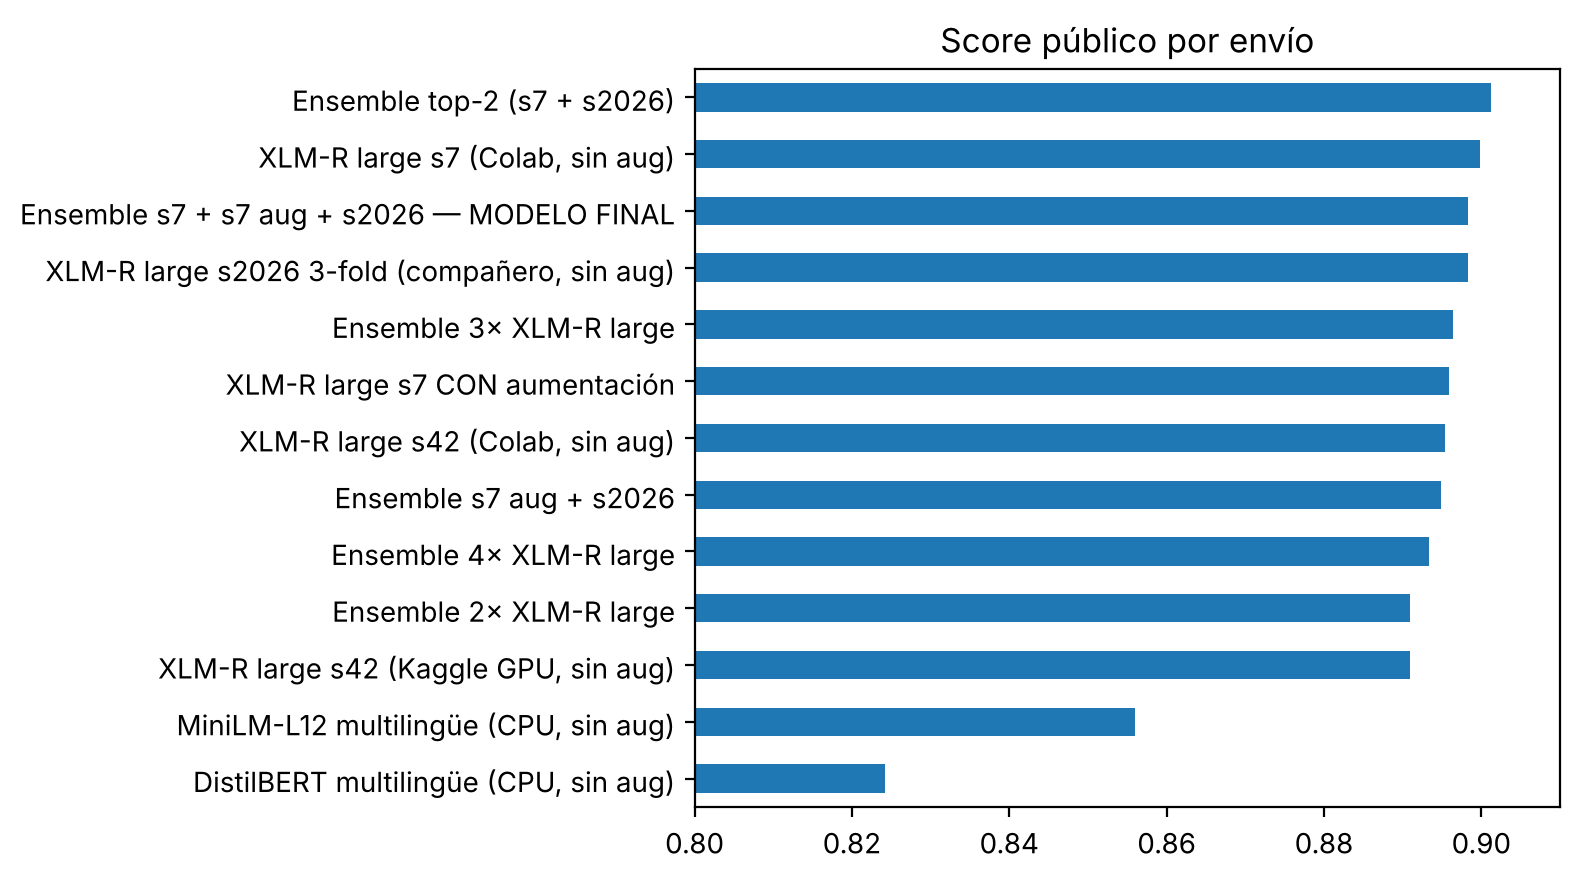

Nota: el público usa solo una parte de eval; diferencias < 0.005 equivalen a ~15 reseñas y no son concluyentes.


In [11]:
it = pd.DataFrame([
    ('TF-IDF + LogReg (Parte 1, no-DL)', 'referencia', f'CV {0.717:.3f}', None, 'n-gramas no comparten información entre idiomas'),
    ('TF-IDF posicional (no-DL)', 'referencia', f'CV {ok_tf.mean():.3f}', None, 'features de última/penúltima oración (+8 pts): el veredicto está al final'),
    ('DistilBERT multilingüe, entrada en par', 'DL', '—', PUBLIC['DistilBERT multilingüe (CPU, sin aug)'], 'primer transformer; modelo chico (CPU)'),
    ('MiniLM-L12 multilingüe, entrada en par', 'DL', 'val 0.887', PUBLIC['MiniLM-L12 multilingüe (CPU, sin aug)'], 'mejor preentrenamiento multilingüe'),
    ('XLM-R large s42', 'DL', '—', PUBLIC['XLM-R large s42 (Colab, sin aug)'], 'modelo grande multilingüe: +4 pts, sobre todo en en/pt/fr'),
    ('XLM-R large s7 (holdout 8 %)', 'DL', 'val (ver 6a)', PUBLIC['XLM-R large s7 (Colab, sin aug)'], 'otra semilla/partición: varianza entre corridas ~0.5 pts'),
    ('XLM-R large s2026, 3 folds', 'DL', '—', PUBLIC['XLM-R large s2026 3-fold (compañero, sin aug)'], 'promedio de 3 folds'),
    ('Ensembles de 2/3/4 XLM-R large', 'DL', '—', PUBLIC['Ensemble 3× XLM-R large'], 'en el público quedan entre los individuales (diferencias dentro del ruido)'),
    ('Ensemble 2 mejores (s7 + s2026)', 'DL', '—', PUBLIC['Ensemble top-2 (s7 + s2026)'], 'promedio de los dos mejores sin aumentación: mejor público'),
    ('XLM-R large s7 + aumentación por traducción', 'DL', 'val (ver 6a)', PUBLIC['XLM-R large s7 CON aumentación'], 'misma partición que s7 sin aug → comparación directa'),
    ('Ensemble s7 + s7 aug + s2026', 'DL (final)', '—', PUBLIC['Ensemble s7 + s7 aug + s2026 — MODELO FINAL'], 'modelo final seleccionado: combina el modelo con aumentación con los dos mejores'),
], columns=['iteración', 'tipo', 'validación', 'Kaggle público', 'qué cambió / por qué'])
display(it)
pub = pd.Series({k: v for k, v in PUBLIC.items() if v}).sort_values()
ax = pub.plot.barh(figsize=(8, 4.5), title='Score público por envío'); ax.set_xlim(0.8, 0.91); plt.tight_layout(); plt.show()
print('Nota: el público usa solo una parte de eval; diferencias < 0.005 equivalen a ~15 reseñas y no son concluyentes.')

## 9. Modelo final: ensemble de 3 XLM-R large y submission
Modelo final (envío seleccionado en Kaggle) = promedio de las probabilidades de:
1. **XLM-R large semilla 7** (Colab T4, *holdout* 8 %, sin aumentación) — público 0.89980
2. **XLM-R large semilla 7 con aumentación por traducción** (misma partición) — público 0.89587
3. **XLM-R large semilla 2026, 3 folds** (Kaggle P100) — público 0.89833

Score público del ensemble: **0.89833**. Elegimos este y no el top-2 (0.90127) porque **incluye el modelo entrenado con
aumentación** (requisito del enunciado), su validación por idioma es mejor en en/fr, y la diferencia en el público (~10 reseñas)
está dentro del ruido. Abajo se reconstruye la submission desde las probabilidades guardadas de cada modelo. Los pesos de los
modelos (`model.safetensors`, PyTorch) se entregan aparte por tamaño (~2.2 GB c/u) — ver enlace en el documento de referencias.

In [12]:
pa = np.load('resultados/probs_colab_s7.npy'); pb = np.load('resultados/probs_colab_s7_aug.npy'); pc = np.load('resultados/probs_compa_s2026.npy')
final = (pa + pb + pc) / 3
sub = pd.DataFrame({'id': ev.id, 'answer': [LABELS[i] for i in final.argmax(1)]})
assert len(sub) == len(ev) and sub.answer.isin(LABELS).all()
sub.to_csv('submission_final.csv', index=False)
print('Distribución de la predicción final:', sub.answer.value_counts(normalize=True).round(3).to_dict())
for n_, p_ in [('s7', pa), ('s7 aug', pb), ('s2026', pc)]: print(f'Acuerdo del ensemble con {n_}: {(final.argmax(1) == p_.argmax(1)).mean():.4f}')
if os.path.exists('resultados/submission_ens3_s7_aug_compa.csv'):
    print('Coincide con la submission enviada a Kaggle:', (pd.read_csv('resultados/submission_ens3_s7_aug_compa.csv').answer.values == sub.answer.values).mean())

Distribución de la predicción final: {'positivo': 0.449, 'negativo': 0.36, 'neutral': 0.191}
Acuerdo del ensemble con s7: 0.9378
Acuerdo del ensemble con s7 aug: 0.9829
Acuerdo del ensemble con s2026: 0.9360
Coincide con la submission enviada a Kaggle: 1.0


## 10. Conclusiones
1. **El modelo multilingüe grande es la decisión que más pesa:** XLM-R large supera a los transformers chicos por 4–7 puntos en el
   público, con la mayor ganancia en inglés, portugués y francés.
2. **La posición importa:** el veredicto suele estar en la última oración; la entrada en par lo hace explícito.
3. **Aumentación:** ver sección 6 (efecto medido con la misma partición y semilla).
4. **Varianza y ensemble:** entre semillas el público varía ~0.5 pts. El modelo final promedia 3 XLM-R large (uno con
   aumentación): 0.89833 público; el mejor público fue el top-2 sin aumentación (0.90127), dentro del ruido del split público.

**Referencias y uso de IA generativa:** ver `docs/ENTREGABLE_referencias_y_IA.md`.